protótipo ~

In [2]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

In [3]:
base = pd.read_csv("../data/processed/base_unificada.csv")

pedidos = base.groupby("order_id").agg(
    nota=("review_score", "first"),
    atraso=("dias_atrasados", "first"),
    preco=("price", "sum"),
    frete=("freight_value", "sum"),
    categoria=("product_category_name", "first"),
    pagamento=("payment_type", "first"),
)
pedidos = pedidos.dropna()
print(len(pedidos))

95807


In [4]:
modelo1 = smf.ols("nota ~ atraso + np.log1p(preco) + np.log1p(frete) + C(categoria) + C(pagamento)", data=pedidos).fit()

print(modelo1.params["atraso"])
print(modelo1.pvalues["atraso"])
print(modelo1.rsquared)

-0.03530531639853223
0.0
0.0950493540164784


In [5]:
pedidos["atrasou"] = (pedidos["atraso"] > 0).astype(int)

pedidos["dias_de_atraso"] = pedidos["atraso"].clip(lower=0)
pedidos["dias_adiantado"] = pedidos["atraso"] * -1

pedidos["dias_adiantado"] = pedidos["dias_adiantado"].clip(lower=0)

In [6]:
modelo2 = smf.ols("nota ~ atrasou + dias_de_atraso + dias_adiantado + np.log1p(preco) + np.log1p(frete) + C(categoria) + C(pagamento)", data=pedidos).fit()

print(modelo2.params[["atrasou", "dias_de_atraso", "dias_adiantado"]])
print(modelo2.pvalues[["atrasou", "dias_de_atraso", "dias_adiantado"]])
print(modelo2.rsquared)

atrasou          -1.362357
dias_de_atraso   -0.027407
dias_adiantado    0.006621
dtype: float64
atrasou            0.000000e+00
dias_de_atraso    2.300119e-171
dias_adiantado     1.900148e-33
dtype: float64
0.15654004264272614


faixa
10+ antes      4.322699
0-10 antes     4.242009
1-7 atraso     3.183715
8-14 atraso    1.743135
15+ atraso     1.708583
Name: nota, dtype: float64


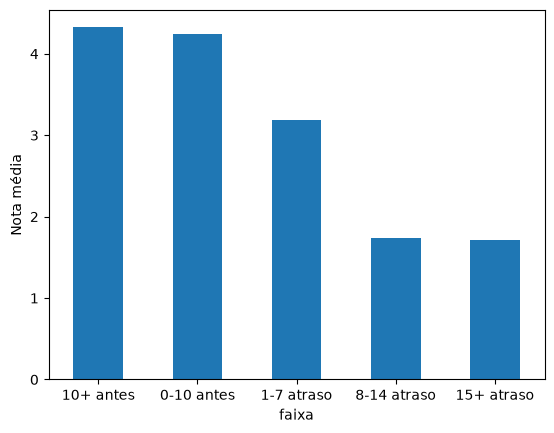

In [9]:
import matplotlib.pyplot as plt

faixas = [-1000, -10, 0, 7, 14, 1000]
nomes = ["10+ antes", "0-10 antes", "1-7 atraso", "8-14 atraso", "15+ atraso"]
pedidos["faixa"] = pd.cut(pedidos["atraso"], bins=faixas, labels=nomes)

nota_por_faixa = pedidos.groupby("faixa")["nota"].mean()
print(nota_por_faixa)

nota_por_faixa.plot(kind="bar")
plt.ylabel("Nota média")
plt.xticks(rotation=0)
plt.show()